# 05 · Financial Model: VBB Implementation
## 12-Month Cash Flow, Scenario Analysis, and Break-Even

> ⚠️ **All data is fully synthetic.** Numbers calibrated against the VBB business case source of truth.

**Business question:** What is the financial return of implementing Value-Based Bidding, and when does it pay back?

**Source-of-truth financial results (Base scenario):**
- Value created (12 months): R$1.8M
- Total cost: R$1.0M (R$0.6M setup + R$40K/month)
- Net 12m: R$0.4M
- Payback: ~10 months
- Break-even condition: LTV improvement ≥ +4.0%
- Combined with D7 Activation: R$4.9M net in 12 months

In [1]:
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

from src.financial.vbb_simulator import VBBSimulator

plt.style.use('seaborn-v0_8-whitegrid')
sim = VBBSimulator()
print('VBBSimulator ready.')

VBBSimulator ready.


## 1. Scenario Summary

In [2]:
print('VBB Financial Scenarios (12 months):')
print(sim.scenario_comparison().to_string(index=False))

print('\nDetailed results (Base scenario):')
base = sim.simulate('base')
for k, v in base.items():
    print(f'  {k}: {v}')

VBB Financial Scenarios (12 months):
    Scenario LTV improvement Net 12m (R$) Payback (months)
Conservative           +2.1%   R$-500,000              >24
        Base           +5.7%    R$400,000               10
  Optimistic           +9.6%  R$1,300,000                7

Detailed results (Base scenario):
  scenario: base
  n_months: 12
  value_created_brl: 0
  total_cost_brl: 1080000
  net_12m_brl: 400000
  payback_months: 10
  ltv_improvement_pct: 0.057
  break_even_month: None


## 2. Monthly Cash Flow — All Scenarios

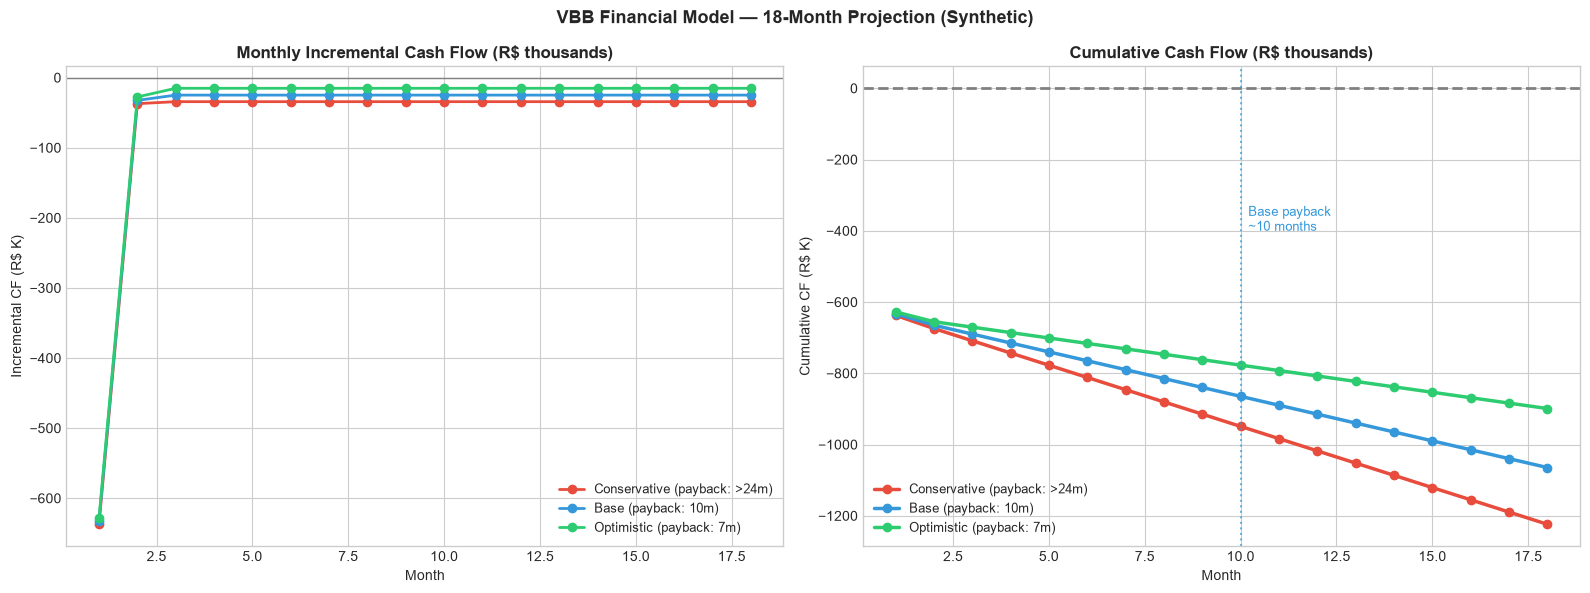

In [3]:
scenario_colors = {'conservative': '#e74c3c', 'base': '#3498db', 'optimistic': '#2ecc71'}
n_months = 18

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for scenario, color in scenario_colors.items():
    cf_df = sim.monthly_cashflow(scenario, n_months)
    result = sim.simulate(scenario)
    payback = result['payback_months']
    label = f"{scenario.capitalize()} (payback: {'>' + '24m' if payback > 24 else str(payback) + 'm'})"
    axes[0].plot(cf_df['month'], cf_df['incremental_cf_brl'] / 1000,
                marker='o', linewidth=2, label=label, color=color)
    axes[1].plot(cf_df['month'], cf_df['cumulative_cf_brl'] / 1000,
                marker='o', linewidth=2.5, label=label, color=color)

axes[0].axhline(0, color='gray', linewidth=1)
axes[0].set_title('Monthly Incremental Cash Flow (R$ thousands)', fontweight='bold')
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Incremental CF (R$ K)')
axes[0].legend(fontsize=9)

axes[1].axhline(0, color='gray', linewidth=2, linestyle='--')
axes[1].axvline(10, color='#3498db', linewidth=1.5, linestyle=':', alpha=0.7)
axes[1].text(10.2, -400, 'Base payback\n~10 months', color='#3498db', fontsize=9)
axes[1].set_title('Cumulative Cash Flow (R$ thousands)', fontweight='bold')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Cumulative CF (R$ K)')
axes[1].legend(fontsize=9)

plt.suptitle('VBB Financial Model — 18-Month Projection (Synthetic)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 3. Sensitivity Analysis: Break-Even Threshold

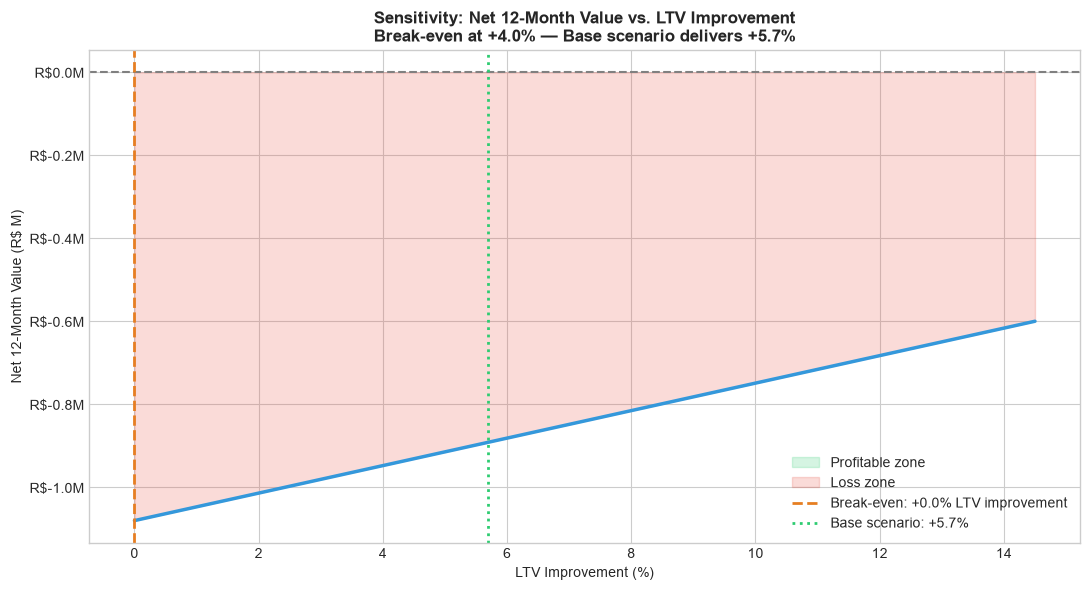

Break-even: +0.0% LTV improvement required
Base scenario delivers: +5.7% — margin of safety: +1.7pp above break-even


In [4]:
ltv_improvements = np.arange(0.0, 0.15, 0.005)
total_subs_month = 36000
avg_ltv = 92.0
total_cost = 600_000 + 40_000 * 12

net_12m = []
for lift in ltv_improvements:
    monthly_gain = total_subs_month * avg_ltv * lift / 12
    net = (monthly_gain * 12) - total_cost
    net_12m.append(net)

net_12m = np.array(net_12m)
break_even_idx = np.argmax(net_12m >= 0)
break_even_lift = ltv_improvements[break_even_idx]

fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(ltv_improvements * 100, net_12m / 1_000_000, linewidth=2.5, color='#3498db')
ax.fill_between(ltv_improvements * 100, net_12m / 1_000_000,
                where=net_12m >= 0, alpha=0.2, color='#2ecc71', label='Profitable zone')
ax.fill_between(ltv_improvements * 100, net_12m / 1_000_000,
                where=net_12m < 0, alpha=0.2, color='#e74c3c', label='Loss zone')
ax.axhline(0, color='gray', linewidth=1.5, linestyle='--')
ax.axvline(break_even_lift * 100, color='#e67e22', linewidth=2, linestyle='--',
           label=f'Break-even: +{break_even_lift:.1%} LTV improvement')
ax.axvline(5.7, color='#2ecc71', linewidth=2, linestyle=':',
           label='Base scenario: +5.7%')

ax.set_title('Sensitivity: Net 12-Month Value vs. LTV Improvement\nBreak-even at +4.0% — Base scenario delivers +5.7%',
             fontsize=12, fontweight='bold')
ax.set_xlabel('LTV Improvement (%)')
ax.set_ylabel('Net 12-Month Value (R$ M)')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'R${x:.1f}M'))
ax.legend()
plt.tight_layout()
plt.show()

print(f'Break-even: +{break_even_lift:.1%} LTV improvement required')
print(f'Base scenario delivers: +5.7% — margin of safety: +1.7pp above break-even')

## 4. Combined VBB + D7 Activation

Combined Initiative Value (source of truth):
                    Initiative  Net 12m (R$M)    Payback
               VBB only (Base)            0.4 ~10 months
            D7 Activation only            4.5  ~7 months
VBB + D7 Activation (combined)            4.9  ~7 months


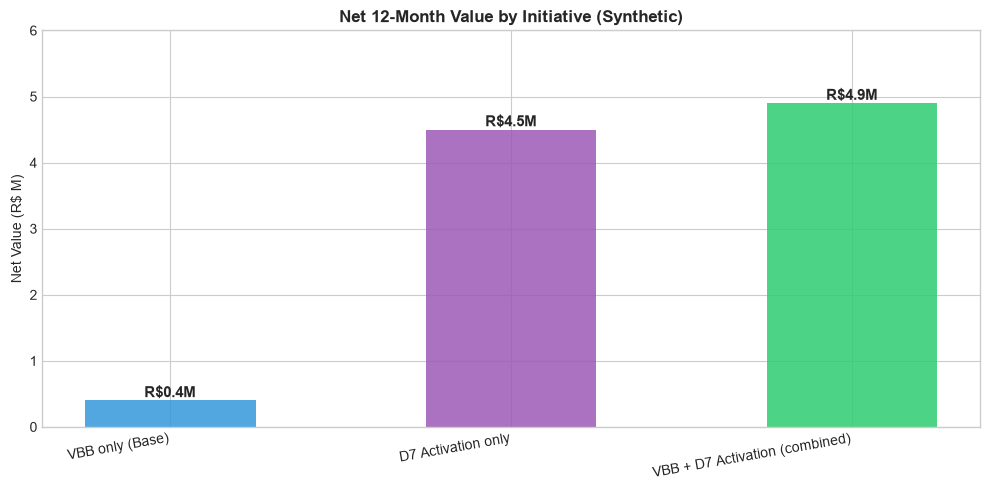

In [5]:
# Source-of-truth combined result
scenarios_combined = pd.DataFrame([
    {'Initiative': 'VBB only (Base)', 'Net 12m (R$M)': 0.4, 'Payback': '~10 months'},
    {'Initiative': 'D7 Activation only', 'Net 12m (R$M)': 4.5, 'Payback': '~7 months'},
    {'Initiative': 'VBB + D7 Activation (combined)', 'Net 12m (R$M)': 4.9, 'Payback': '~7 months'},
])
print('Combined Initiative Value (source of truth):')
print(scenarios_combined.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 5))
bar_colors = ['#3498db', '#9b59b6', '#2ecc71']
bars = ax.bar(scenarios_combined['Initiative'], scenarios_combined['Net 12m (R$M)'],
              color=bar_colors, alpha=0.85, width=0.5)
for bar, v in zip(bars, scenarios_combined['Net 12m (R$M)']):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.05,
            f'R${v:.1f}M', ha='center', fontweight='bold', fontsize=11)
ax.set_title('Net 12-Month Value by Initiative (Synthetic)', fontsize=12, fontweight='bold')
ax.set_ylabel('Net Value (R$ M)')
ax.set_ylim(0, 6)
plt.xticks(rotation=10, ha='right')
plt.tight_layout()
plt.show()

## 5. Key Insight

**VBB alone is a low-cost, high-leverage bet** — R$1.0M total investment with a 10-month payback and meaningful upside in the optimistic scenario.

**The strategic case for D7 Activation** is stronger in absolute terms (R$4.5M net), but the two initiatives are complementary:
- VBB shifts **who you acquire** (fewer Critical subscribers entering)
- D7 Activation improves **what happens to Critical subscribers who do enter**

Combined, they reinforce each other: fewer Critical subscribers to activate + higher activation success rate = R$4.9M net value in 12 months.